# **Project Name** - **Voyage Analytics - Exploratory Data Analysis**
##### **Project Type** - EDA + Hypothesis Testing
##### **Contribution** - Team (3 members)

# **Problem Statement**
**Voyage Analytics** is a travel-tech capstone built on three datasets - *users*, *flights* and *hotels* - with a dual goal:
(1) use them to make better travel decisions with machine learning, and (2) learn MLOps by productionising those models
(REST API -> Docker -> Kubernetes -> Airflow -> Jenkins CI/CD -> MLflow -> Streamlit).

**Business objective of this notebook:** understand who travels, where, on what class/agency, what they pay, and where they
stay - and find out which variables can legitimately drive the prediction models built in notebooks 02-04.

## ***1. Know Your Data***
### Import Libraries & Load Data

In [1]:
import sys, warnings, pathlib
warnings.filterwarnings("ignore")
ROOT = pathlib.Path.cwd().resolve().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from voyage import config, data
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 30)

In [2]:
users, flights, hotels = data.load_users(), data.load_flights(), data.load_hotels()
for n, d in [('users', users), ('flights', flights), ('hotels', hotels)]:
    print(f'--- {n}: {d.shape[0]:,} rows x {d.shape[1]} cols'); display(d.head(3))

--- users: 1,340 rows x 5 cols


,code,company,name,gender,age
0,0,4You,Roy Braun,male,21
1,1,4You,Joseph Holsten,male,37
2,2,4You,Wilma Mcinnis,female,48


--- flights: 271,888 rows x 10 cols


,travelCode,userCode,from,to,flightType,price,time,distance,agency,date
0,0,0,Recife (PE),Florianopolis (SC),firstClass,1434.38,1.76,676.53,FlyingDrops,2019-09-26
1,0,0,Florianopolis (SC),Recife (PE),firstClass,1292.29,1.76,676.53,FlyingDrops,2019-09-30
2,1,0,Brasilia (DF),Florianopolis (SC),firstClass,1487.52,1.66,637.56,CloudFy,2019-10-03


--- hotels: 40,552 rows x 8 cols


,travelCode,userCode,name,place,days,price,total,date
0,0,0,Hotel A,Florianopolis (SC),4,313.02,1252.08,2019-09-26
1,2,0,Hotel K,Salvador (BH),2,263.41,526.82,2019-10-10
2,7,0,Hotel K,Salvador (BH),3,263.41,790.23,2019-11-14


### Dataset Information, Duplicates, Missing Values

In [3]:
for n, d in [('users', users), ('flights', flights), ('hotels', hotels)]:
    print(f"{n:8s} duplicates={d.duplicated().sum()}  missing cells={int(d.isna().sum().sum())}")
print('\nFlight dates :', flights.date.min().date(), '->', flights.date.max().date())
print('Hotel dates  :', hotels.date.min().date(), '->', hotels.date.max().date())
flights.info()

users    duplicates=0  missing cells=0
flights  duplicates=0  missing cells=0
hotels   duplicates=0  missing cells=0

Flight dates : 2019-09-26 -> 2023-07-24
Hotel dates  : 2019-09-26 -> 2023-07-13
<class 'pandas.DataFrame'>
RangeIndex: 271888 entries, 0 to 271887
Data columns (total 10 columns):
 #   Column      Non-Null Count   Dtype         
---  ------      --------------   -----         
 0   travelCode  271888 non-null  int64         
 1   userCode    271888 non-null  int64         
 2   from        271888 non-null  str           
 3   to          271888 non-null  str           
 4   flightType  271888 non-null  str           
 5   price       271888 non-null  float64       
 6   time        271888 non-null  float64       
 7   distance    271888 non-null  float64       
 8   agency      271888 non-null  str           
 9   date        271888 non-null  datetime64[us]
dtypes: datetime64[us](1), float64(3), int64(2), str(4)
memory usage: 32.4 MB


### What did you know about your dataset?
* **users** (1,340) - `code`, `company`, `name`, `gender` (male / female / **none**), `age` (21-65).
* **flights** (271,888) - one row per flight leg: route (`from`, `to`), `flightType` (economic / premium / firstClass), `price`, `time`, `distance`, `agency`, `date`.
* **hotels** (40,552) - one row per stay: `name`, `place`, `days`, `price` (per night), `total`, `date`.
* **No missing values and no duplicates** - the data is clean; the challenge is in what the data *cannot* tell us (see the findings below).
* `travelCode` + `userCode` link a trip's flights and hotel stay; `userCode` links everything to `users.code`.

## ***2. Understanding Your Variables***

In [4]:
display(flights.describe().round(2)); display(hotels.describe().round(2)); display(users.describe().round(2))
print(flights[['from','to','flightType','agency']].nunique())

,travelCode,userCode,price,time,distance,date
count,271888.00,271888.00,271888.00,271888.00,271888.00,271888
mean,67971.50,667.51,957.38,1.42,546.96,2021-01-11 05:25:56.052492
min,0.00,0.00,301.51,0.44,168.22,2019-09-26 00:00:00
25%,33985.75,326.00,672.66,1.04,401.66,2020-04-02 00:00:00
50%,67971.50,659.00,904.00,1.46,562.14,2020-11-14 00:00:00
75%,101957.25,1011.00,1222.24,1.76,676.53,2021-09-09 00:00:00
max,135943.00,1339.00,1754.17,2.44,937.77,2023-07-24 00:00:00
std,39243.72,389.52,362.31,0.54,208.85,NaN


,travelCode,userCode,days,price,total,date
count,40552.00,40552.00,40552.00,40552.00,40552.00,40552
mean,67911.79,666.96,2.50,214.44,536.23,2021-01-10 05:22:32.219372
min,0.00,0.00,1.00,60.39,60.39,2019-09-26 00:00:00
25%,33696.75,323.00,1.00,165.99,247.62,2020-04-02 00:00:00
50%,67831.00,658.00,2.00,242.88,495.24,2020-11-12 00:00:00
75%,102211.25,1013.00,4.00,263.41,742.86,2021-09-09 00:00:00
max,135942.00,1339.00,4.00,313.02,1252.08,2023-07-13 00:00:00
std,39408.20,391.14,1.12,76.74,319.33,NaN


,code,age
count,1340.00,1340.00
mean,669.50,42.74
std,386.97,12.87
min,0.00,21.00
25%,334.75,32.00
50%,669.50,42.00
75%,1004.25,54.00
max,1339.00,65.00


from          9
to            9
flightType    3
agency        3
dtype: int64


## ***3. Data Wrangling***

In [5]:
# Integrity checks that matter for modelling
print('Distinct distances per route (should be 1):', flights.groupby(['from','to']).distance.nunique().max())
print('|time/distance| spread (constant speed?):', (flights.time/flights.distance).agg(['min','max']).round(5).to_dict())
print('hotel total == days*price for all rows :', bool(((hotels.days*hotels.price - hotels.total).abs() < 0.05).all()))
print('Distinct price per hotel               :', hotels.groupby('name').price.nunique().max())
print('Hotel city == flight destination (same trip):',
      round((hotels.merge(flights.sort_values('date').groupby(['travelCode','userCode']).head(1)[['travelCode','userCode','to']],
             on=['travelCode','userCode']).eval('place == to')).mean(), 3))
# Is price a pure function of (route, class, agency)?
g = flights.groupby(['from','to','flightType','agency']).price.std()
print('Max price std within (route, class, agency):', round(float(g.max()), 4), f'over {len(g)} combinations')

Distinct distances per route (should be 1): 1
|time/distance| spread (constant speed?): {'min': 0.00259, 'max': 0.00262}
hotel total == days*price for all rows : True
Distinct price per hotel               : 1


Hotel city == flight destination (same trip): 1.0
Max price std within (route, class, agency): 0.0 over 490 combinations


### What manipulations have you done and insights you found?
Four structural facts fall out of the integrity checks - each one drives a modelling decision later:
1. **`time` is a constant multiple of `distance`** (correlation 1.000) -> keep `distance`, drop `time` to avoid perfect multicollinearity.
2. **Each route has exactly one distance**, so an API can accept just `from`/`to` and look the distance up server-side.
3. **Flight price is fully determined by (route, flightType, agency)**: the standard deviation within every one of the 490 combinations is 0. Prices are a fixed price table, so a regression model can reach R² ≈ 1 legitimately (this is *not* leakage - no target-derived column is used) but it also means dates add nothing.
4. **Each hotel is in exactly one city with one fixed nightly price, and the hotel city always equals the flight destination of the same trip** - that makes destination the strongest recommendation signal.

## ***4. Data Visualization, Storytelling & Experimenting with charts***

#### Chart - 1 - Flight class mix (Univariate)

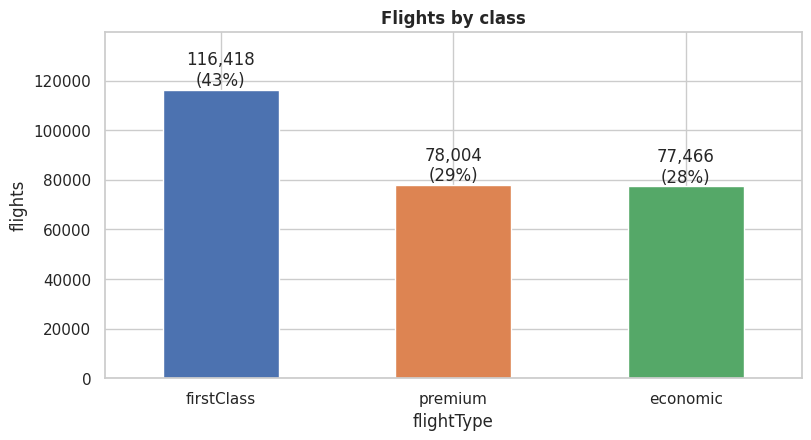

In [6]:
c = flights.flightType.value_counts()
ax = c.plot.bar(color=sns.color_palette()[:3]); ax.set_ylabel('flights'); ax.set_title('Flights by class')
for i, v in enumerate(c): ax.text(i, v, f'{v:,}\n({v/len(flights):.0%})', ha='center', va='bottom')
plt.xticks(rotation=0); plt.ylim(0, c.max()*1.2); plt.show()

##### 1. Why did you pick the specific chart?
A bar chart is the clearest way to compare the size of a handful of categories.
##### 2. What is/are the insight(s) found from the chart?
First class is the largest segment (**116,418 flights, 43%**), ahead of premium (78,004; 29%) and economic (77,466; 28%). This is an unusually premium-heavy customer base.
##### 3. Will the gained insights help creating a positive business impact?
Yes - revenue is concentrated in first class, so pricing, capacity and upsell strategy should be built around it; a price model must be very accurate on first class.

#### Chart - 2 - Price distribution by class (Bivariate: categorical vs numeric)

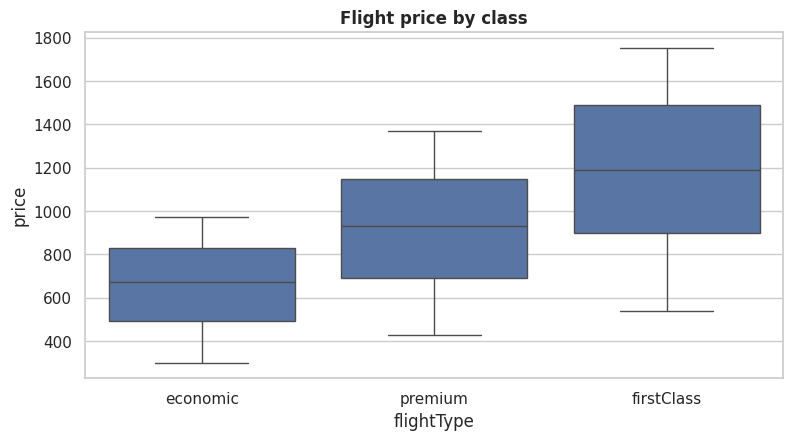

              mean  median    std
flightType                       
economic     658.0   675.0  193.0
firstClass  1181.0  1191.0  346.0
premium      920.0   933.0  277.0


In [7]:
sns.boxplot(data=flights, x='flightType', y='price', order=['economic','premium','firstClass']); plt.title('Flight price by class'); plt.show()
print(flights.groupby('flightType').price.agg(['mean','median','std']).round(0))

##### 1. Why did you pick the specific chart?
Box plots show median, spread and overlap between groups at once.
##### 2. What is/are the insight(s) found from the chart?
Mean price rises cleanly with class: **economic ≈ 658, premium ≈ 920, first class ≈ 1,181**. The classes overlap substantially, so class alone does not fix the price - route matters too.
##### 3. Will the gained insights help creating a positive business impact?
Yes - a clear class premium (~1.8x economic for first class) supports tiered pricing and is a key feature for the regression model.

#### Chart - 3 - Agency price - the confounding trap (Bivariate + Multivariate)

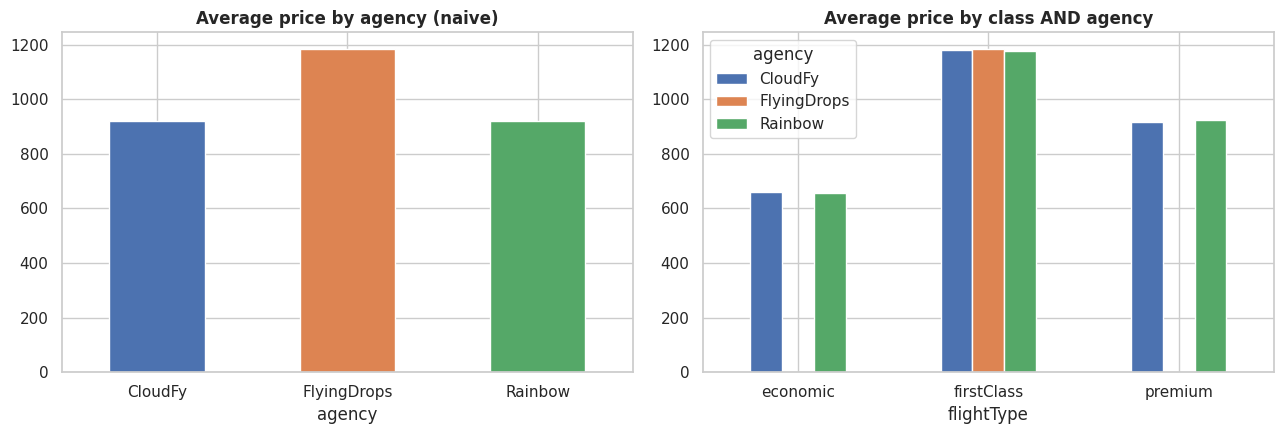

flightType   economic  firstClass  premium
agency                                    
CloudFy          0.33        0.33     0.33
FlyingDrops       NaN        1.00      NaN
Rainbow          0.33        0.33     0.34


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
flights.groupby('agency').price.mean().plot.bar(ax=ax[0], color=sns.color_palette()[:3], rot=0); ax[0].set_title('Average price by agency (naive)')
flights.groupby(['flightType','agency']).price.mean().unstack().plot.bar(ax=ax[1], rot=0); ax[1].set_title('Average price by class AND agency')
plt.tight_layout(); plt.show()
print(flights.groupby('agency').flightType.value_counts(normalize=True).unstack().round(2))

##### 1. Why did you pick the specific chart?
Placing the naive view next to the class-split view exposes a classic Simpson's-paradox style confound.
##### 2. What is/are the insight(s) found from the chart?
Naively **FlyingDrops looks ~30% more expensive (≈1,186 vs ≈919)**. But **FlyingDrops sells *only* first-class tickets** while CloudFy and Rainbow sell a 1/3-1/3-1/3 mix of all classes. Within first class the three agencies charge nearly the same (≈1,177-1,186, a gap under 1%).
##### 3. Will the gained insights help creating a positive business impact?
Yes - it prevents a wrong business conclusion. Agencies differ mainly in product mix, not in price. Any agency recommendation must control for class.

#### Chart - 4 - Destinations - volume and price (Univariate + Bivariate)

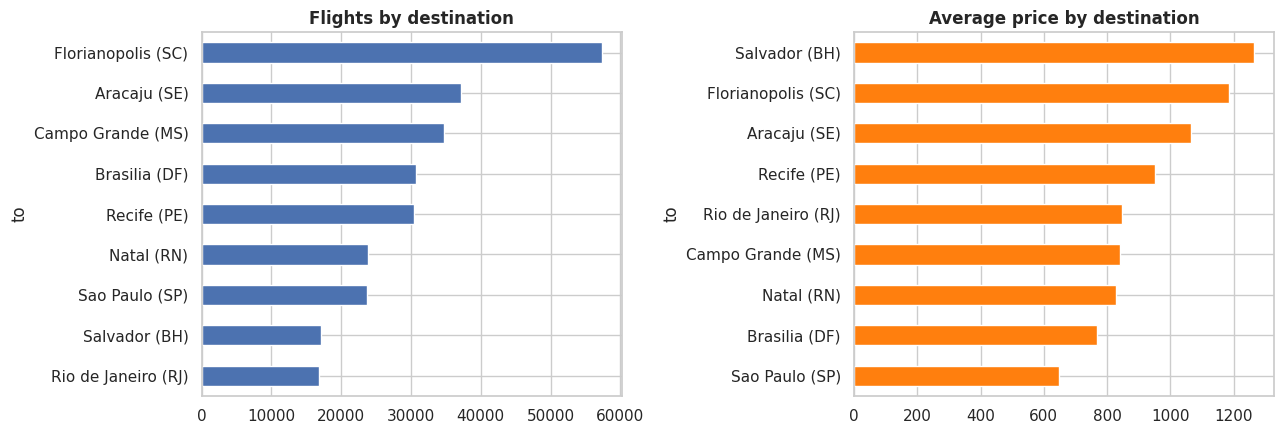

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
flights.groupby('to').size().sort_values().plot.barh(ax=ax[0]); ax[0].set_title('Flights by destination')
flights.groupby('to').price.mean().sort_values().plot.barh(ax=ax[1], color='tab:orange'); ax[1].set_title('Average price by destination')
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?
Horizontal bars keep the long city names readable and rank cities at a glance.
##### 2. What is/are the insight(s) found from the chart?
**Florianopolis is the top destination (57,317 flights, 21%)**, followed by Aracaju (37,224) and Campo Grande (34,748). **Salvador is the most expensive (≈1,264 avg) and Sao Paulo the cheapest (≈648).**
##### 3. Will the gained insights help creating a positive business impact?
Yes - capacity planning and marketing should prioritise Florianopolis; Salvador routes carry the highest per-ticket revenue.

#### Chart - 5 - Price vs distance (Bivariate: numeric vs numeric)

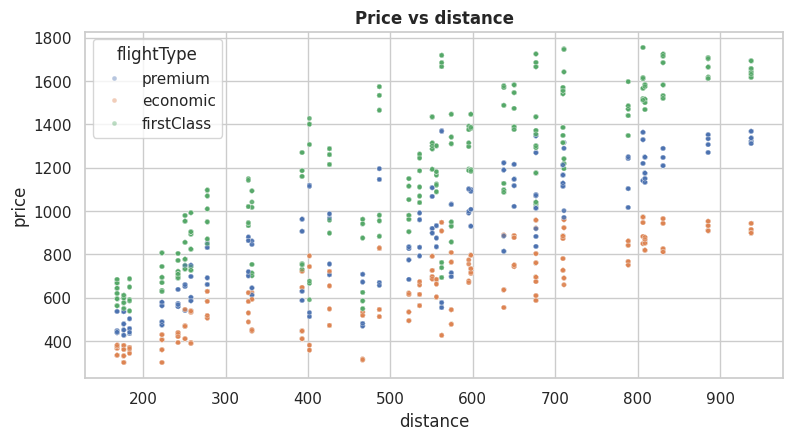

          price  distance   time
price     1.000     0.642  0.642
distance  0.642     1.000  1.000
time      0.642     1.000  1.000


In [10]:
s = flights.sample(15000, random_state=1)
sns.scatterplot(data=s, x='distance', y='price', hue='flightType', alpha=.4, s=12); plt.title('Price vs distance'); plt.show()
print(flights[['price','distance','time']].corr().round(3))

##### 1. Why did you pick the specific chart?
A scatter plot reveals the shape of a relationship and colour reveals the class structure.
##### 2. What is/are the insight(s) found from the chart?
Price rises with distance (**r = 0.64**) but forms three separate class bands. `time` and `distance` are perfectly correlated (**r = 1.00**) - redundant.
##### 3. Will the gained insights help creating a positive business impact?
Yes - distance is a legitimate driver of price and `time` can be dropped from the model with zero information loss.

#### Chart - 6 - Demand over time (Time series)

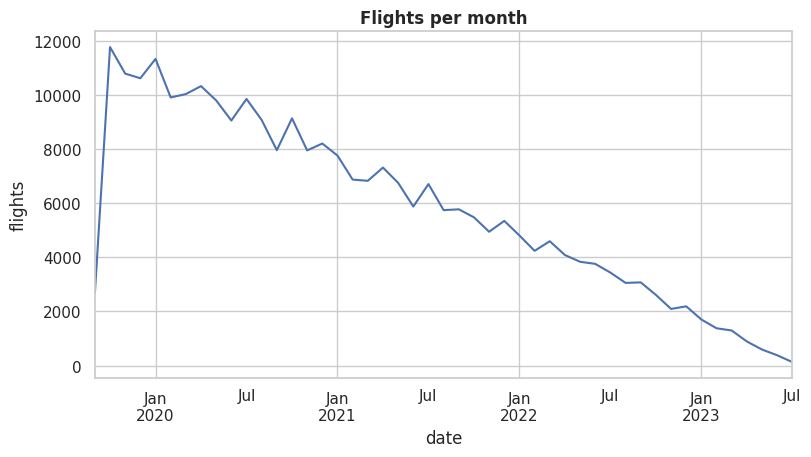

date
2019     35826
2020    112571
2021     75363
2022     41761
2023      6367
dtype: int64


In [11]:
m = flights.set_index('date').resample('MS').size()
m.plot(); plt.title('Flights per month'); plt.ylabel('flights'); plt.show()
print(flights.groupby(flights.date.dt.year).size())

##### 1. Why did you pick the specific chart?
A line chart is the standard way to see trend and seasonality.
##### 2. What is/are the insight(s) found from the chart?
The window runs **26 Sep 2019 -> 24 Jul 2023**. Volume peaks in **2020 (112,571 flights)** and declines afterwards (2021: 75,363; 2022: 41,761; 2023 partial: 6,367). The pattern does not follow real-world travel seasonality, which is one of the signs that this is a synthetic dataset - we treat time effects with caution.
##### 3. Will the gained insights help creating a positive business impact?
Partly - trend monitoring is useful for MLOps drift checks, but forecasting from this pattern would not be credible.

#### Chart - 7 - Hotels - bookings vs revenue (Bivariate)

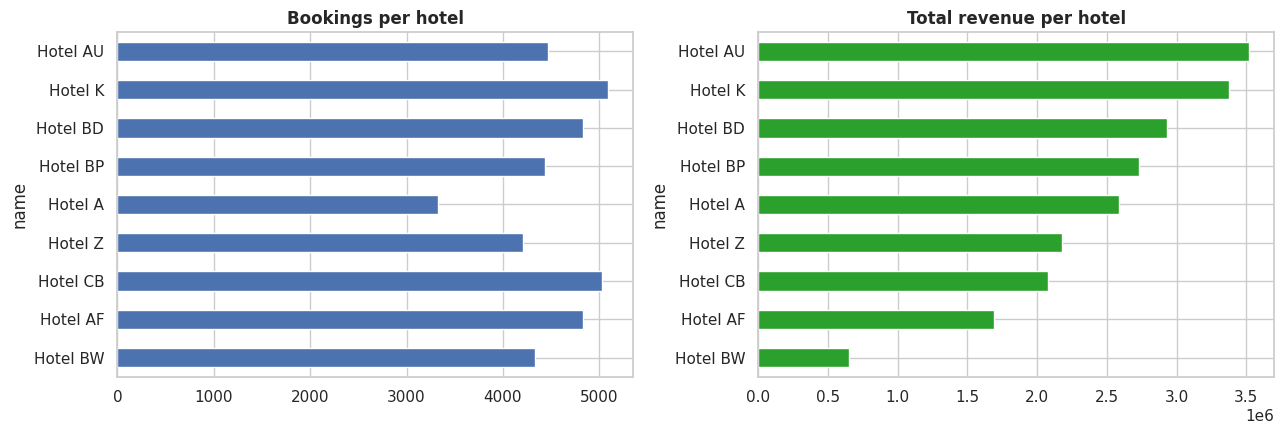

,bookings,price,revenue
name,,,
Hotel BW,4333,60.0,652997.0
Hotel AF,4828,139.0,1686727.0
Hotel CB,5029,166.0,2075207.0
Hotel Z,4205,208.0,2179635.0
Hotel A,3330,313.0,2588362.0
Hotel BP,4437,248.0,2731744.0
Hotel BD,4829,243.0,2931076.0
Hotel K,5094,263.0,3376653.0
Hotel AU,4467,313.0,3522779.0


In [12]:
hb = hotels.groupby('name').agg(bookings=('total','size'), price=('price','first'), revenue=('total','sum')).sort_values('revenue')
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
hb.bookings.plot.barh(ax=ax[0]); ax[0].set_title('Bookings per hotel')
hb.revenue.plot.barh(ax=ax[1], color='tab:green'); ax[1].set_title('Total revenue per hotel')
plt.tight_layout(); plt.show(); display(hb.round(0))

##### 1. Why did you pick the specific chart?
Two aligned bar charts contrast popularity (volume) with value (revenue).
##### 2. What is/are the insight(s) found from the chart?
**Hotel K (5,094) and Hotel CB (5,029) are the most booked**, but **Hotel AU earns the most (≈3.52M)** thanks to a ≈313/night rate. **Hotel BW is the cheapest (≈60/night) and lowest revenue (≈0.65M)**. Hotel A is the least booked (3,330).
##### 3. Will the gained insights help creating a positive business impact?
Yes - popularity and revenue rank hotels differently, so a recommender should be able to weigh price/budget, not just popularity.

#### Chart - 8 - Length of stay and customers (Univariate)

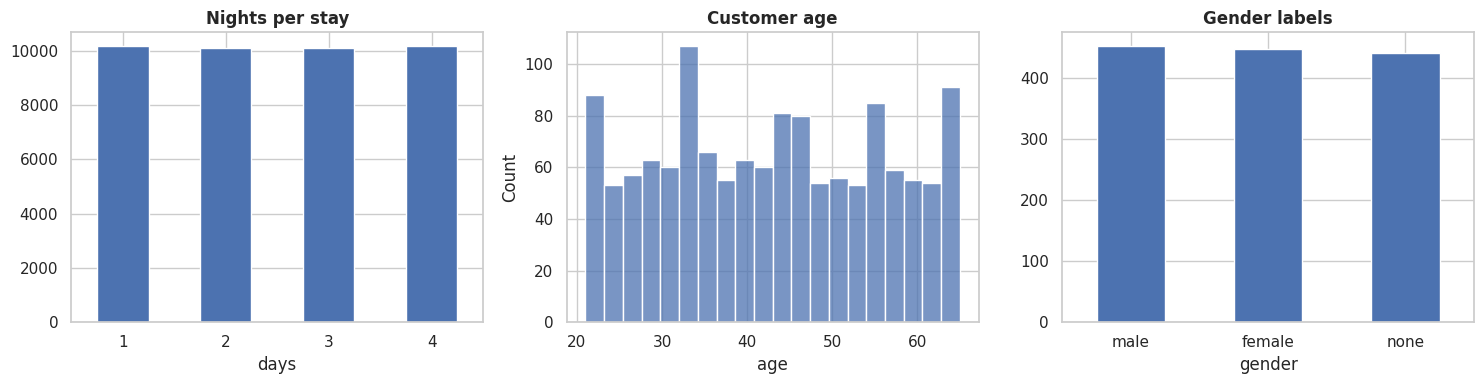

company
4You             453
Acme Factory     261
Wonka Company    237
Monsters CYA     195
Umbrella LTDA    194
Name: count, dtype: int64


In [13]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
hotels.days.value_counts().sort_index().plot.bar(ax=ax[0], rot=0); ax[0].set_title('Nights per stay')
sns.histplot(users.age, bins=20, ax=ax[1]); ax[1].set_title('Customer age')
users.gender.value_counts().plot.bar(ax=ax[2], rot=0); ax[2].set_title('Gender labels')
plt.tight_layout(); plt.show(); print(users.company.value_counts())

##### 1. Why did you pick the specific chart?
Small-multiple charts profile the three key univariate distributions side by side.
##### 2. What is/are the insight(s) found from the chart?
Stays are **exactly uniform: 25% each for 1-4 nights**. Customers are aged **21-65 (mean ≈ 42.7)**. Gender labels are almost perfectly balanced: **male 452, female 448, none 440**; 4You is the largest company (453 users).
##### 3. Will the gained insights help creating a positive business impact?
Yes - a uniform stay length and balanced gender classes mean no single 'typical' stay to optimise, and balanced classes make gender modelling fair to evaluate (chance = 33%).

#### Chart - 9 - Correlation heatmap (Multivariate)

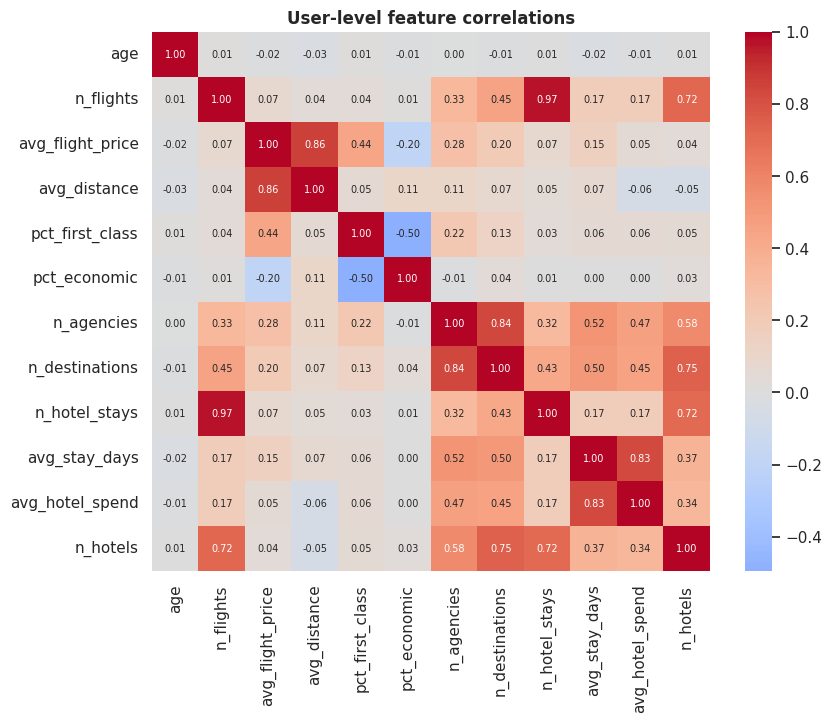

In [14]:
uf = data.user_behaviour_features(users, flights, hotels)
num = uf.select_dtypes('number').drop(columns='userCode')
plt.figure(figsize=(9, 7)); sns.heatmap(num.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, annot_kws={'size': 7}); plt.title('User-level feature correlations'); plt.show()

##### 1. Why did you pick the specific chart?
A heatmap summarises all pairwise linear relationships in one view.
##### 2. What is/are the insight(s) found from the chart?
Behavioural features are largely uncorrelated with `age`, and per-user averages (flight price, spend) barely relate to each other - users behave like independent random draws from the same population.
##### 3. Will the gained insights help creating a positive business impact?
Yes - it warns us early that user-level prediction tasks (like gender) will have very little signal to learn from.

## ***5. Hypothesis Testing***
Four statements were derived from the charts above.

In [15]:
from scipy import stats
# H1: first class costs more than economic  (one-tailed Mann-Whitney U on equal-size samples)
fc = flights[flights.flightType=='firstClass'].price.sample(20000, random_state=1)
ec = flights[flights.flightType=='economic'].price.sample(20000, random_state=1)
print('H1  first > economic  : p =', stats.mannwhitneyu(fc, ec, alternative='greater').pvalue)

# H2: within first class, the three agencies charge the same average price (one-way ANOVA)
fcl = flights[flights.flightType=='firstClass']
print('H2  agency (1st class): p =', round(stats.f_oneway(*[g.price for _, g in fcl.groupby('agency')]).pvalue, 4),
      '| means', fcl.groupby('agency').price.mean().round(1).to_dict())

# H3: average hotel spend is the same across the 3 gender labels (ANOVA, user level)
print('H3  gender vs spend   : p =', round(stats.f_oneway(*[g.avg_hotel_spend for _, g in uf.groupby('gender')]).pvalue, 4))

# H4: gender is independent of company (chi-square)
print('H4  gender x company  : p =', round(stats.chi2_contingency(pd.crosstab(uf.company, uf.gender))[1], 4))

H1  first > economic  : p = 0.0
H2  agency (1st class): p = 0.0007 | means {'CloudFy': 1180.3, 'FlyingDrops': 1186.2, 'Rainbow': 1176.8}
H3  gender vs spend   : p = 0.2578
H4  gender x company  : p = 0.375


| # | Null hypothesis (H0) | Alternate (H1) | Test | Result |
|---|---|---|---|---|
| H1 | mean first-class price = economic | first class > economic | Mann-Whitney U (right-tailed; skew-robust) | **Reject H0** (p ≈ 0) - first class is genuinely pricier |
| H2 | agencies charge the same within first class | at least one differs | One-way ANOVA | **Reject H0** (p ≈ 0.0007) - but the gap is only ≈ 9 (< 1%), i.e. statistically detectable because n is huge, **not practically meaningful** |
| H3 | hotel spend equal across gender labels | differs | One-way ANOVA | **Fail to reject** (p ≈ 0.26) |
| H4 | gender independent of company | dependent | Chi-square | **Fail to reject** (p ≈ 0.37) |

H3 and H4 are an early warning that **gender is not related to spending behaviour or employer** in this data.

## ***6. Solution to Business Objective & Conclusion***
1. **Prices are a price table** - route + class + agency fully determine the fare. The regression model is therefore legitimately near-perfect; dates and `time` add nothing.
2. **Agency 'premium' is a mix effect** - FlyingDrops only sells first class. Compare agencies within a class (differences there are < 1%).
3. **Florianopolis / first class / Hotel AU** are the volume and value anchors of the business.
4. **Hotel city == flight destination** - the recommender should use the destination whenever it is known.
5. **User attributes (gender/age/company) are essentially independent of behaviour** - so the gender classifier should be expected to perform near chance (verified in notebook 03).
6. The data window and volume pattern look **synthetic**; use it to demonstrate the MLOps pipeline, and be cautious about real-world claims.

### ***Hurrah! You have successfully completed the EDA part of the capstone!!!***